https://rbrooksdk.github.io/STA1_26/assignments/assignment_04_one_and_two_sample_tests/

# Assignment 4 — One- and Two-Sample Tests
**Group members:** Daniel Munteanu, Josip Brljevic, Luca Mouawad, Zygmunt Tadeusz Kwasniewicz

## Table of contents
1. Part 1 — One-sample decisions
2. Part 2 — Independent coating processes
3. Part 3 — Paired building-energy measurements
4. Part 4 — Comparing two independent proportions
5. Part 5 — AI-use and conclusion

In [93]:
from IPython.display import display, Markdown
import scipy.stats as stats
from statsmodels.stats.proportion import proportion_confint
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import math

In [94]:
sensor = pd.read_csv("data/assignment03_sensor_calibration.csv")
access = pd.read_csv("data/assignment03_access_control.csv")
coating = pd.read_csv("data/assignment04_coating_durability.csv")
energy = pd.read_csv("data/assignment04_energy_retrofit.csv")

# Part 1 — One-sample decisions
## Mean sensor error
#### Use assignment03_sensor_calibration.csv. The engineering team asks whether population mean calibration error differs from zero; errors with absolute mean below $0.50\,^\circ C$ are regarded as small in practice.
### a) State $H_0$, the two-sided $H_1$, and $\alpha=0.05$. Use a one-sample $t$ procedure and report the sample mean, test statistic, degrees of freedom, and two-sided $p$-value.

In [95]:
t = stats.t
sensor.head(5)

,sensor_id,calibration_error_c
0,1,0.334
1,2,0.383
2,3,1.644
3,4,0.627
4,5,0.615


In [96]:
# t 
calibration_errors = sensor["calibration_error_c"]
n = calibration_errors.size
sample_mean = calibration_errors.mean()
sample_std = calibration_errors.std()
sample_standard_error = (sample_std / math.sqrt(n))
t_obs = (sample_mean - 0) / sample_standard_error
sample_df = n - 1
p_two = 2 * t.sf(np.abs(t_obs), df=sample_df)


display(Markdown(f"""
$H_0$: $\\mu = 0$ (mean error is zero) \\
$H_1$: $\\mu \\neq 0$ (mean error is not zero) \\
$\\alpha = 0.05$ \\
$\\hat x = {sample_mean}$ \\
standard error $ = {sample_standard_error}$ \\
test statistic $ = t = {t_obs}$ \\
$v = n - 1 = {sample_df}$ \\
two-sided $p$-value $= {p_two}$ 
"""))


$H_0$: $\mu = 0$ (mean error is zero) \
$H_1$: $\mu \neq 0$ (mean error is not zero) \
$\alpha = 0.05$ \
$\hat x = 0.188265625$ \
standard error $ = 0.07821836878490106$ \
test statistic $ = t = 2.4069234365872125$ \
$v = n - 1 = 63$ \
two-sided $p$-value $= 0.019030535831259087$ 


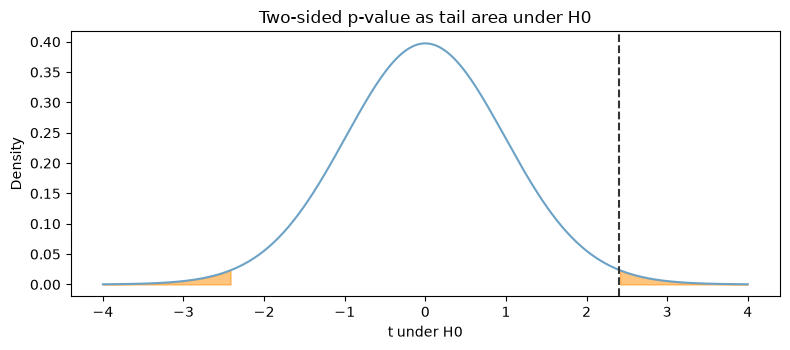

In [97]:
grid = np.linspace(-4, 4, 400)
pdf = t.pdf(grid, df=n - 1)
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(grid, pdf, color="#6CA2C6")
ax.fill_between(grid, pdf, where=grid <= -abs(t_obs), color="#FF8C00", alpha=0.5)
ax.fill_between(grid, pdf, where=grid >= abs(t_obs), color="#FF8C00", alpha=0.5)
ax.axvline(t_obs, color="0.2", linestyle="--")
ax.set_xlabel("t under H0")
ax.set_ylabel("Density")
ax.set_title("Two-sided p-value as tail area under H0")
plt.tight_layout()
plt.show()

### b) Interpret the $p$-value as a tail probability conditional on $H_0$ and the assumptions. State the decision and a contextual conclusion without treating the $p$-value as $P(H_0\mid\text{data})$.

In [98]:
should_reject = p_two < 0.05
display(Markdown(f"""
$p$-value $= {p_two}$  \\
this p value means there would be a ~~ 2% probability of getting the data we analysed assuming that $H_0$ was actually true \\
$\\alpha =$ 0.05 \\
should $H_0$ be rejected? {should_reject} since {round(p_two, 4)} < 0.05 \\
so while $H_0$ must be rejected, in practical terms our mean error is {sample_mean} which is less then the practically acceptable error of 0.5C
"""))


$p$-value $= 0.019030535831259087$  \
this p value means there would be a ~~ 2% probability of getting the data we analysed assuming that $H_0$ was actually true \
$\alpha =$ 0.05 \
should $H_0$ be rejected? True since 0.019 < 0.05 \
so while $H_0$ must be rejected, in practical terms our mean error is 0.188265625 which is less then the practically acceptable error of 0.5C


### c) Reuse or reconstruct the 95% $t$ interval and explain its duality with this two-sided test. Compare it with the practical limits and distinguish statistical significance from practical importance.

In [99]:
t_critical = t.ppf(1 - (0.05/2), sample_df)
ci_95_low = sample_mean - t_critical * sample_standard_error
ci_95_high = sample_mean + t_critical * sample_standard_error

display(Markdown(f"""
95% t interval: [{ci_95_low:.4f}, {ci_95_high:.4f}] \\
0 lies outside of the 95% t interval so we would again reject $H_0$
but while statisitcally important, practically we were informed that 0.5C is considered a small error, and 0 +- 0.5C does easily lie in the 95% t interval
"""))


95% t interval: [0.0320, 0.3446] \
0 lies outside of the 95% t interval so we would again reject $H_0$
but while statisitcally important, practically we were informed that 0.5C is considered a small error, and 0 +- 0.5C does easily lie in the 95% t interval


## False-rejection probability
#### Use assignment03_access_control.csv. The pre-specified question is whether the false-rejection probability exceeds the 5% target.
### d) State the one-sided hypotheses. Perform an exact binomial test and report $\hat p$, the $p$-value, decision, and conclusion.

In [100]:
access.head(5)

,attempt_id,false_reject
0,1,0
1,2,0
2,3,0
3,4,1
4,5,0


In [101]:
fr = access["false_reject"]
k = fr.sum()
n = fr.count()
p_hat = k / n

bi = stats.binomtest(k=fr.sum(), 
                     n=fr.count(), 
                     p=0.05,
                     alternative="greater")

display(Markdown(f"""
$H_0$: $\\mu = 0.05 $  
$H_1$: $\\mu > 0.05 $  
$\\hat p = {p_hat}$ \\
$p$-value $= {bi.pvalue}$ \\
This means that we observed $8\\%$ of the sample requests be falsely rejects 
So with the data given, the probability of such an event occuring, had $H_0$ been true, would be around $1.8\\%$. \\
As such, assuming a significance level of $\\alpha = 0.05$, the hypothesis $H_0$ ought to be rejectd
"""))


$H_0$: $\mu = 0.05 $  
$H_1$: $\mu > 0.05 $  
$\hat p = 0.08333333333333333$ \
$p$-value $= 0.018485562994802782$ \
This means that we observed $8\%$ of the sample requests be falsely rejects 
So with the data given, the probability of such an event occuring, had $H_0$ been true, would be around $1.8\%$. \
As such, assuming a significance level of $\alpha = 0.05$, the hypothesis $H_0$ ought to be rejectd


### e) Use the Wilson interval as an estimate of plausible values, while explaining why a two-sided Wilson interval is not the exact dual of a one-sided exact test.

In [102]:
wilson = proportion_confint(count=k, nobs=n, alpha=0.05, method='wilson')
display(Markdown(f"""
95% wilson = {tuple(np.round(wilson, 4))} \\
We are 95% sure that the actual probability of rejecting a request is somewhere between 0.0546 and 0.1252, which makes it outside of our assumed 5% rejection rate.
Wilson is not a dual of the test above as wilson includes both tails, upper and lower and due to our hypothesis being upper-tailed we only care about the upper tail
"""))


95% wilson = (np.float64(0.0546), np.float64(0.1252)) \
We are 95% sure that the actual probability of rejecting a request is somewhere between 0.0546 and 0.1252, which makes it outside of our assumed 5% rejection rate.
Wilson is not a dual of the test above as wilson includes both tails, upper and lower and due to our hypothesis being upper-tailed we only care about the upper tail


### f) Describe Type I and Type II errors in one of the two one-sample studies and state an operational consequence of each.

In [103]:
display(Markdown(f"""
Type I error would be Incorrectly rejecting a hypothesis that is in actuality true, given the access control study this could result in wasted efforts, as the company would be busy fixing an issue that doesn't exist.
Type II error means failing to reject a hypothesis that is in actuality false, this would mean that an issue goes undetected and in the context of the access control a large number of legitimate requests would be rejected, and this issue would go unnoticed.
"""))


Type I error would be Incorrectly rejecting a hypothesis that is in actuality true, given the access control study this could result in wasted efforts, as the company would be busy fixing an issue that doesn't exist.
Type II error means failing to reject a hypothesis that is in actuality false, this would mean that an issue goes undetected and in the context of the access control a large number of legitimate requests would be rejected, and this issue would go unnoticed.


# Part 2 — Independent coating processes
#### The file assignment04_coating_durability.csv contains independent specimens from a standard and modified coating process. Let $\delta=\mu_{\text{modified}}-\mu_{\text{standard}}$, measured in durability hours. An increase of at least 8 hours is considered practically important.
### a) Explain why the samples are independent rather than paired. Report group $n$, mean, sample standard deviation, and boxplots.

,n,mean,sd
process,,,
standard,44,117.29,15.75
modified,48,132.49,22.19


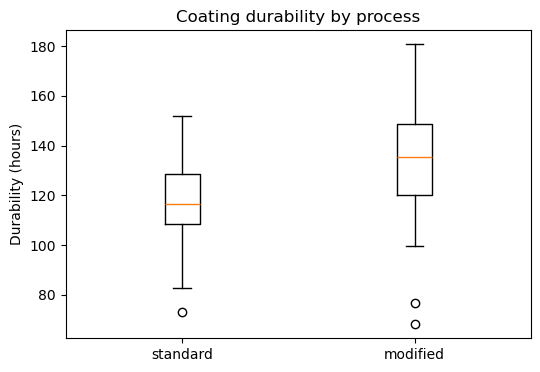

In [6]:
order = ["standard", "modified"]
coating_summary = coating.groupby("process")["durability_h"].agg(n="count", mean="mean", sd="std").loc[order].round(2)
display(coating_summary)

fig, ax = plt.subplots(figsize=(6, 4))
ax.boxplot([coating.loc[coating["process"] == p, "durability_h"] for p in order])
ax.set_xticklabels(order)
ax.set_ylabel("Durability (hours)")
ax.set_title("Coating durability by process")
plt.show()

The samples are independent because each specimen was coated with only one process and measured once. The groups also have different sizes (44 and 48), so the specimens cannot be paired. \
The modified process has a higher mean (132.49 h vs 117.29 h) and a larger standard deviation (22.19 h vs 15.75 h). \
The boxes overlap partly and the whiskers overlap a lot. The standard group has one low outlier (72.9 h) and the modified group has two (68.1 h and 76.5 h).

### b) State two-sided hypotheses about $\delta$. Use Welch's two-sample $t$ procedure and report the estimated difference, 95% confidence interval, statistic, approximate degrees of freedom, and $p$-value. Do not use a preliminary variance test to switch automatically between pooled and Welch procedures.

In [12]:
modified = coating.loc[coating["process"] == "modified", "durability_h"]
standard = coating.loc[coating["process"] == "standard", "durability_h"]

welch = stats.ttest_ind(modified, standard, equal_var=False)  # equal_var=False -> Welch, not pooled
diff = modified.mean() - standard.mean()

v1 = modified.var(ddof=1) / len(modified)
v2 = standard.var(ddof=1) / len(standard)
se = np.sqrt(v1 + v2)
df = (v1 + v2)**2 / (v1**2 / (len(modified) - 1) + v2**2 / (len(standard) - 1))  # Welch–Satterthwaite
t_crit = stats.t.ppf(0.975, df)
ci = (diff - t_crit * se, diff + t_crit * se)

display(Markdown(rf"""
$H_0$: $\delta = 0$ (no difference in mean durability) \
$H_1$: $\delta \neq 0$ \
$\alpha = 0.05$ \
estimated difference = {diff:.2f} h \
standard error = {se:.2f} h \
95% CI = ({ci[0]:.2f}, {ci[1]:.2f}) h \
test statistic $t$ = {welch.statistic:.2f} \
degrees of freedom = {df:.1f} \
two-sided $p$-value = {welch.pvalue:.5f} \
Since $p$ < 0.05 we reject $H_0$. The modified process lasts longer on average, by about {diff:.1f} hours.
"""))


$\delta = \mu_{modified} - \mu_{standard}$ (hours) <br>
$H_0: \delta = 0$ &emsp; $H_1: \delta \neq 0$ &emsp; $\alpha = 0.05$

| estimate $\hat\delta$ | SE | 95% CI | $t$ | df | $p$ |
| ---: | ---: | ---: | ---: | ---: | ---: |
| 15.20 h | 3.99 h | (7.27, 23.13) h | 3.81 | 84.8 | 0.00026 |

$p < 0.05$, so we reject $H_0$: the modified process has a higher mean durability, by about 15.2 h (95% CI 7.3 to 23.1 h).


### c) Assess independence from the design and distribution shape and unusual observations from group plots or residual diagnostics. State what the plots cannot establish.

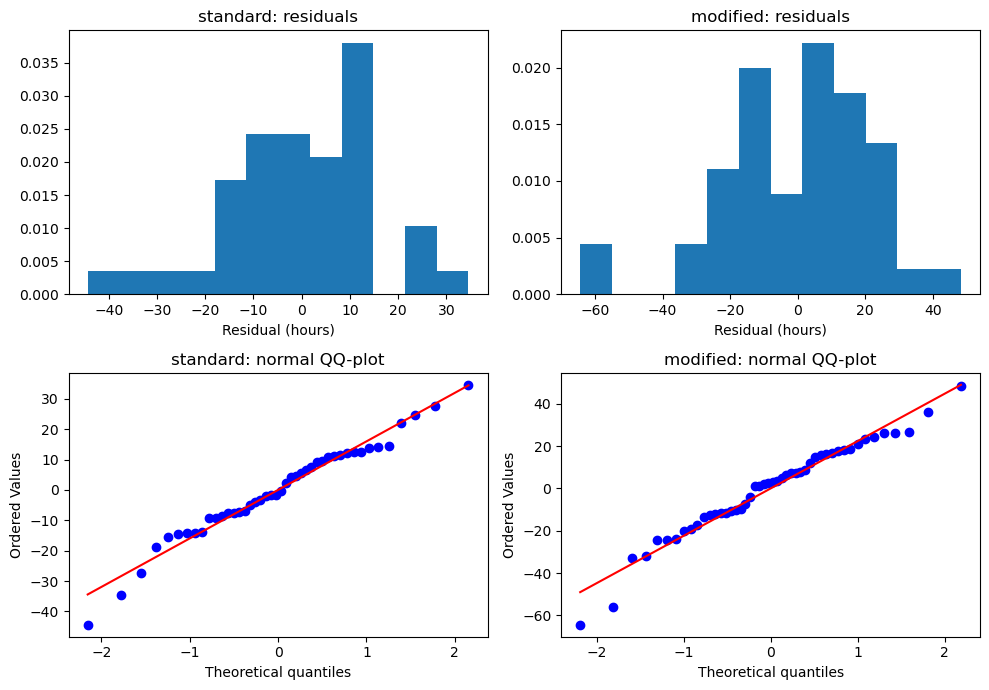

,specimen_id,process,durability_h
24,25,standard,72.93
70,71,modified,76.48
88,89,modified,68.12



Without outliers: $\hat\delta$ = 16.78 h, 95% CI (9.81, 23.76) h, $p$ = 0.000007


In [ ]:
residual = coating["durability_h"] - coating.groupby("process")["durability_h"].transform("mean")

fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for i, p in enumerate(order):
    res = residual[coating["process"] == p]
    axes[0, i].hist(res, bins=12, density=True)
    axes[0, i].set_title(f"{p}: residuals")
    axes[0, i].set_xlabel("Residual (hours)")
    stats.probplot(res, dist="norm", plot=axes[1, i])
    axes[1, i].set_title(f"{p}: normal QQ-plot")
plt.tight_layout()
plt.show()

q1 = coating.groupby("process")["durability_h"].transform(lambda x: x.quantile(0.25))
q3 = coating.groupby("process")["durability_h"].transform(lambda x: x.quantile(0.75))
iqr = q3 - q1
is_outlier = (coating["durability_h"] < q1 - 1.5 * iqr) | (coating["durability_h"] > q3 + 1.5 * iqr)
display(coating.loc[is_outlier, ["specimen_id", "process", "durability_h"]])

kept = coating.loc[~is_outlier]
mod_k = kept.loc[kept["process"] == "modified", "durability_h"]
std_k = kept.loc[kept["process"] == "standard", "durability_h"]
welch_k = stats.ttest_ind(mod_k, std_k, equal_var=False)
diff_k = mod_k.mean() - std_k.mean()
v1_k = mod_k.var(ddof=1) / len(mod_k)
v2_k = std_k.var(ddof=1) / len(std_k)
se_k = np.sqrt(v1_k + v2_k)
df_k = (v1_k + v2_k)**2 / (v1_k**2 / (len(mod_k) - 1) + v2_k**2 / (len(std_k) - 1))
ci_k = (diff_k - stats.t.ppf(0.975, df_k) * se_k, diff_k + stats.t.ppf(0.975, df_k) * se_k)
display(Markdown(rf"""
Without the outliers: estimated difference = {diff_k:.2f} h, 95% CI = ({ci_k[0]:.2f}, {ci_k[1]:.2f}) h, $p$-value = {welch_k.pvalue:.6f}
"""))

Independence cannot be checked with plots. It comes from the design: different specimens, each coated with one process and measured once. \
The QQ-plots mostly follow the line, but both groups have a few low values below it (a longer lower tail). With 44 and 48 specimens the sample means are still close to normal because of the CLT, so the Welch test is reasonable. \
There are three low outliers (specimens 25, 71 and 89). Without them the estimated difference is 16.8 h with CI (9.8, 23.8) h, so the conclusion does not change. We keep them since there is no reason to think they are errors. \
The plots cannot show whether the specimens are really independent (for example same batch or test day), whether they represent future production, or why the outliers failed early.

### d) Compare the interval with both zero and the 8-hour practical threshold. Give a recommendation that reflects statistical uncertainty and practical importance.

The 95% CI (7.27, 23.13) h lies entirely above 0, so the modified process has a higher mean durability. \
The estimate of 15.2 h is above the 8 hour threshold, but the lower end of the interval (7.27 h) is just below it. So we cannot be sure the improvement is at least 8 hours. \
Without the three outliers the interval is (9.8, 23.8) h, which is fully above 8 h. \
Recommendation: the modified process most likely gives a practically important improvement, but the evidence is not strong enough to be certain. If switching is cheap it can be adopted, otherwise more specimens should be tested and the early failures investigated first.

# Part 3 — Paired building-energy measurements
#### The file assignment04_energy_retrofit.csv records energy use for the same 36 buildings before and after a control-system retrofit. Define the paired difference $D=\text{before}-\text{after}$, so a positive value represents a reduction.
### a) Explain the observational unit and why the rows form genuine pairs. Create the difference column and report its mean, standard deviation, and standard error.

### b) Plot the paired values and the distribution or QQ-plot of differences. Diagnose the differences—not the two raw columns separately—for the paired $t$ procedure.

### c) Test $H_0:\mu_D=0$ against a two-sided alternative and construct a 95% interval for $\mu_D$, using `ttest_rel` or an equivalent one-sample procedure applied to the differences.

### d) Explain why an independent-samples test would discard useful pairing. Interpret the estimated reduction and interval in kWh/day and state a practical recommendation.

# Part 4 — Comparing two independent proportions
#### Two independently assigned software configurations were evaluated using separate requests. Configuration A had 38 SLA failures among 300 requests; configuration B had 22 among 320. Define the risk difference as $p_A-p_B$.
### a) State the observational unit, binary outcome, populations, assumptions, comparison order, and two-sided hypotheses.

### b) Calculate both sample proportions, their difference in percentage points, and a 95% confidence interval using separate estimated variances.

### c) Test $H_0:p_A=p_B$ with a two-proportion $z$ procedure. Report $z$, the two-sided $p$-value, decision, and contextual conclusion.

### d) State what random sampling and random assignment would each support and why a significant difference alone is not enough for an unrestricted causal claim.

# Part 5 — AI-use and conclusion
## AI-use

## Overall conclusion